# Phase 1 – Raw-data inventory (native resolution)

**Goal:** know every signal before we change anything. Every reading is used exactly as logged: no averaging, no filtering, no fixes.

For each signal this notebook shows:
1. **Inventory table:** unit, how often it logs, gaps, duplicates, zeros, negatives, range, stuck values
2. **Coverage:** which signals have data on which days
3. **Per-signal view:** distribution of all readings, and daily low / median / high over the year
4. **Checks of known suspected issues** (drafts, negative shaft values, torque units, placeholder weather, Jan 2025)

**How to use it:** split the signals between us. For each of yours, read its row in the table and its two plots, then write down anything odd with evidence (section and numbers). Don't fix anything here; fixes are decided as a team.

**Before running:** `python src/load_raw.py` (writes `data/processed/raw_long/`, takes a few minutes).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

PROCESSED = os.path.join("..", "data", "processed")
raw = pd.read_parquet(os.path.join(PROCESSED, "raw_long"), columns=["time", "signal", "value"])
raw["signal"] = raw.signal.astype("category")
meta = pd.read_csv(os.path.join(PROCESSED, "signals.csv")).set_index("signal")

BLUE, INK, MUTED, GRID = "#2a78d6", "#1f1f1e", "#6b6a64", "#e6e5e0"
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 9, "axes.titlesize": 9})
print(f"{len(raw):,} readings, {raw.signal.nunique()} signals, {raw.time.min()} to {raw.time.max()}")
unknown = [s for s in raw.signal.cat.categories if str(s).startswith("unknown:")]
print("readings with an unknown signal id:", int(raw.signal.isin(unknown).sum()))

42,192,373 readings, 36 signals, 2024-01-01 00:00:00+00:00 to 2025-01-31 23:59:45+00:00
readings with an unknown signal id: 0


## 1. Inventory table

| Column | Meaning |
|---|---|
| `interval_s` | most common time between readings (the logging rate) |
| `at_interval_%` | share of steps exactly at that rate |
| `gaps_gt_1h`, `longest_gap_h` | how often and how long the signal is silent |
| `dup_times` | readings with the same timestamp as the previous one |
| `zero_%`, `neg_%` | share of exact zeros and of negative values |
| `top_value`, `top_value_%` | most frequent value; a high share suggests a stuck or placeholder value |
| `longest_stuck_h` | longest run of identical consecutive values, in hours |

The table is also saved to `data/processed/raw_inventory.csv`.

In [2]:
raw = raw.sort_values(["signal", "time"], kind="stable").reset_index(drop=True)

def inventory(g):
    t, v = g.time, g.value
    dt = t.diff().dt.total_seconds().iloc[1:].round(0)   # timestamps jitter by a few ms
    step = dt[dt > 0].mode()
    step = step.iloc[0] if len(step) else np.nan
    same = v.ne(v.shift()).cumsum()                       # run id of identical consecutive values
    runs = g.groupby(same.values).time.agg(["min", "max"])
    vc = v.value_counts(dropna=True)
    q = v.quantile([0.01, 0.5, 0.99])
    return pd.Series({
        "readings": len(g), "first": t.min(), "last": t.max(),
        "interval_s": step, "at_interval_%": 100 * (dt == step).mean() if len(dt) else np.nan,
        "gaps_gt_1h": int((dt > 3600).sum()), "longest_gap_h": dt.max() / 3600 if len(dt) else np.nan,
        "dup_times": int((dt == 0).sum()), "nan": int(v.isna().sum()),
        "zero_%": 100 * (v == 0).mean(), "neg_%": 100 * (v < 0).mean(),
        "min": v.min(), "p1": q[0.01], "median": q[0.5], "p99": q[0.99], "max": v.max(),
        "distinct": v.nunique(), "top_value": vc.index[0] if len(vc) else np.nan,
        "top_value_%": 100 * vc.iloc[0] / len(v) if len(vc) else np.nan,
        "longest_stuck_h": (runs["max"] - runs["min"]).max().total_seconds() / 3600,
    })

inv = raw.groupby("signal", observed=True)[["time", "value"]].apply(inventory)
inv = meta[["quantity_name", "source_name", "unit"]].join(inv, how="right")
inv.to_csv(os.path.join(PROCESSED, "raw_inventory.csv"))
pd.set_option("display.max_columns", 40, "display.width", 250, "display.max_rows", 60)
inv.drop(columns=["quantity_name"]).round(2)

,source_name,unit,readings,first,last,interval_s,at_interval_%,gaps_gt_1h,longest_gap_h,dup_times,nan,zero_%,neg_%,min,p1,median,p99,max,distinct,top_value,top_value_%,longest_stuck_h
signal,,,,,,,,,,,,,,,,,,,,,,
depth_m,Instrument Echosounder,m,648086,2024-01-01 00:00:00.030000+00:00,2025-01-20 03:13:00+00:00,15.0,99.08,47,1055.21,0,0,0.00,0.00,7.000000e-01,1.400000e+00,8.900000e+00,1.633000e+02,8.306000e+02,3819,8.600000e+00,3.86,7.44
draft_aft,Control Alarm Monitoring System,m,2056336,2024-01-01 00:00:00.081000+00:00,2025-01-31 23:59:45+00:00,15.0,99.96,25,538.60,232,0,100.00,0.00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1,0.000000e+00,100.00,9528.00
draft_fwd,Control Alarm Monitoring System,m,2056727,2024-01-01 00:00:00.081000+00:00,2025-01-31 23:59:45+00:00,15.0,99.96,25,538.60,232,0,100.00,0.00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1,0.000000e+00,100.00,9528.00
draft_midp,Control Alarm Monitoring System,m,2056723,2024-01-01 00:00:00.081000+00:00,2025-01-31 23:59:45+00:00,15.0,99.96,25,538.60,232,0,100.00,0.00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1,0.000000e+00,100.00,9528.00
draft_mids,Control Alarm Monitoring System,m,2056736,2024-01-01 00:00:00.081000+00:00,2025-01-31 23:59:45+00:00,15.0,99.96,25,538.60,232,0,100.00,0.00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1,0.000000e+00,100.00,9528.00
fo_kgh,Instrument Torquemeter,kg/hr,1908035,2024-01-01 00:00:00.121000+00:00,2024-12-31 23:59:45.013000+00:00,15.0,99.95,19,538.60,255,0,9.84,0.00,0.000000e+00,0.000000e+00,9.200000e+02,1.454000e+03,4.153000e+03,1499,0.000000e+00,9.84,69.20
heading_deg,Instrument Gyrocompass,degrees,2026909,2024-01-01 00:00:00.030000+00:00,2025-01-29 13:20:45+00:00,15.0,99.92,62,247.18,45,0,0.01,0.00,0.000000e+00,7.700000e+00,1.601000e+02,3.591000e+02,3.599000e+02,3600,3.590000e+02,0.88,19.60
mb_cur_e,Provider MB,m/s,9058,2024-01-01 00:00:00+00:00,2025-01-31 23:00:00+00:00,3600.0,99.56,40,108.00,0,0,19.65,45.05,-1.520000e+00,-7.600000e-01,0.000000e+00,7.100000e-01,1.960000e+00,236,0.000000e+00,19.65,252.00
mb_cur_n,Provider MB,m/s,9058,2024-01-01 00:00:00+00:00,2025-01-31 23:00:00+00:00,3600.0,99.56,40,108.00,0,0,19.73,42.57,-1.360000e+00,-6.400000e-01,0.000000e+00,5.800000e-01,1.440000e+00,212,0.000000e+00,19.73,252.00


## 2. Coverage: readings per day as a share of the logging rate

Dark = full coverage, white = no data. Weather signals log hourly, sensors every 15 s, so each signal is compared with its own rate.

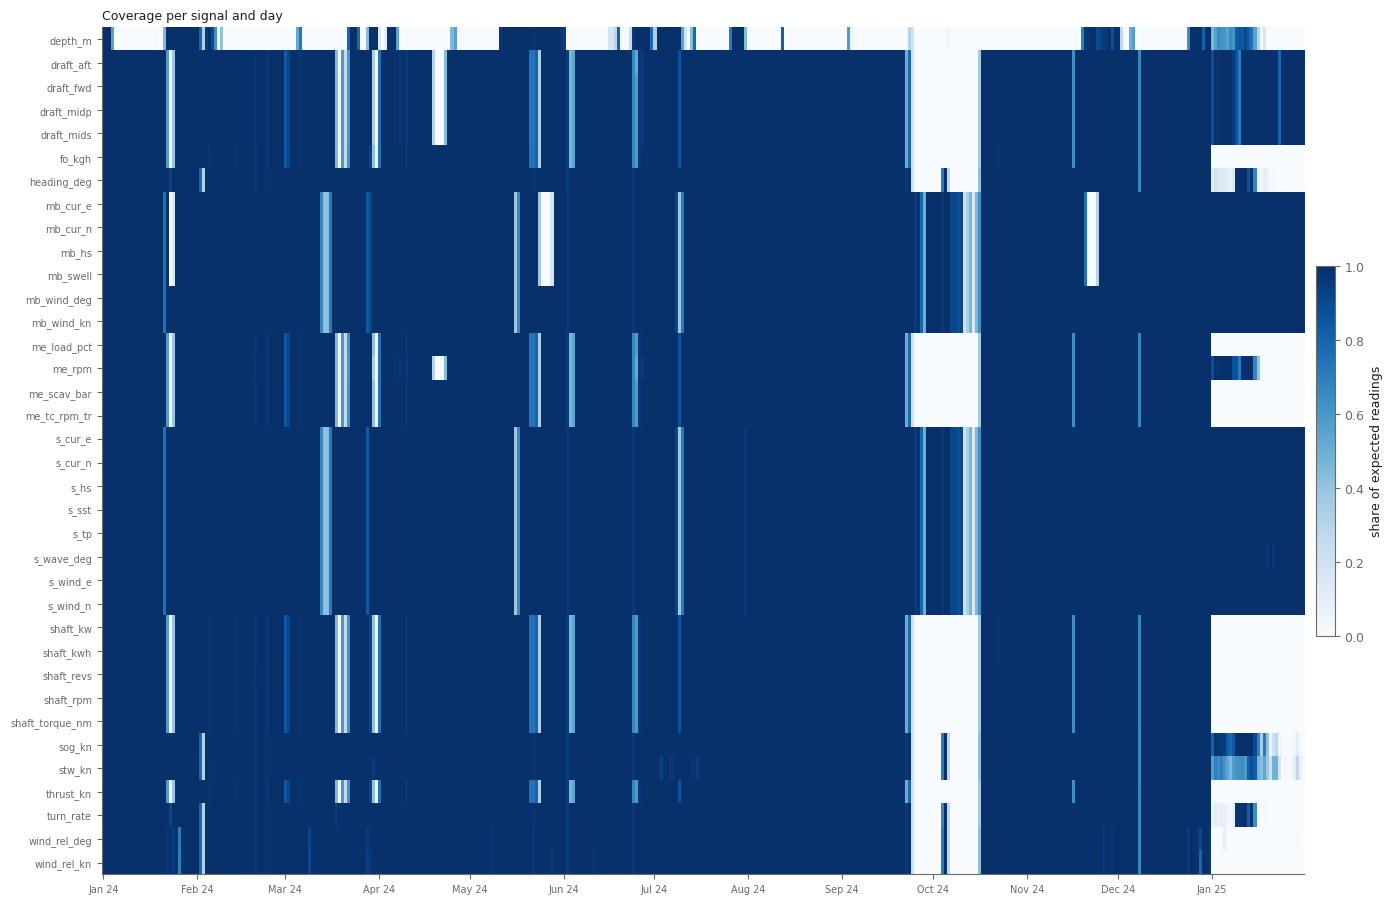

In [3]:
day = raw.time.dt.tz_localize(None).dt.normalize()
cnt = raw.groupby([raw.signal, day], observed=True).size().unstack(fill_value=0)
expected = (86400 / inv.interval_s).reindex(cnt.index)
cov = cnt.div(expected, axis=0).clip(upper=1)
fig, ax = plt.subplots(figsize=(14, 0.22 * len(cov) + 1.2))
im = ax.imshow(cov.values, aspect="auto", cmap="Blues", vmin=0, vmax=1, interpolation="nearest")
ax.set_yticks(range(len(cov))); ax.set_yticklabels(cov.index, fontsize=7)
months = [i for i, d in enumerate(cov.columns) if d.day == 1]
ax.set_xticks(months); ax.set_xticklabels([cov.columns[i].strftime("%b %y") for i in months], fontsize=7)
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.015, pad=0.01, label="share of expected readings")
ax.set_title("Coverage per signal and day", loc="left", color=INK)
fig.tight_layout(); plt.show()

## 3. Per-signal view

Left: histogram of **all** readings, clipped to the 0.5–99.5 percentiles so the shape is visible. The title says how many readings fall outside and the share of exact zeros.
Right: daily 1st percentile, median and 99th percentile over time. Look for steps, drifts, flat lines and sign flips.

To look at one signal: `show("shaft_kw")`.

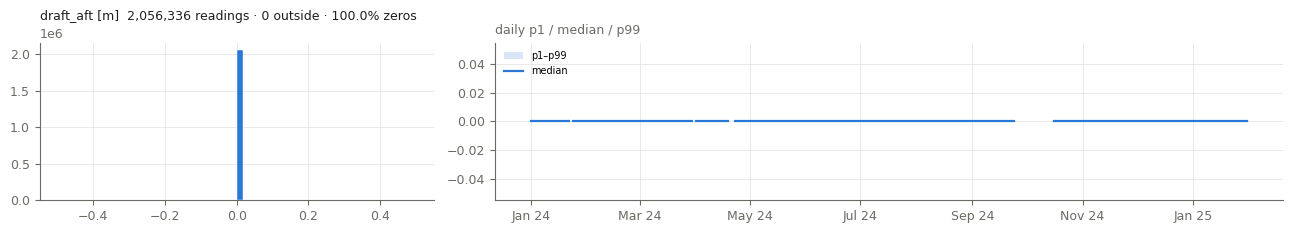

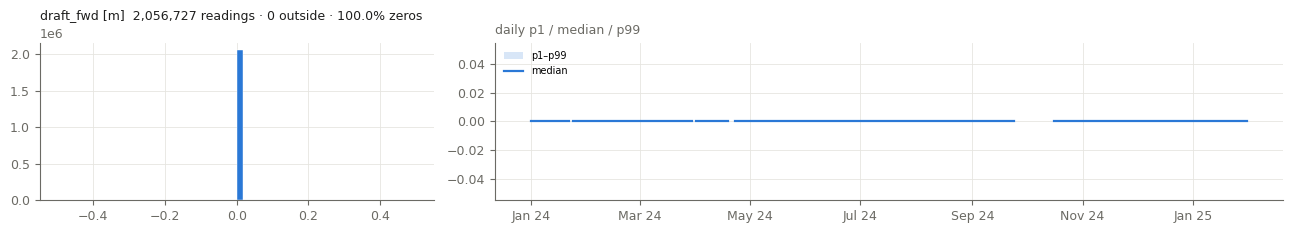

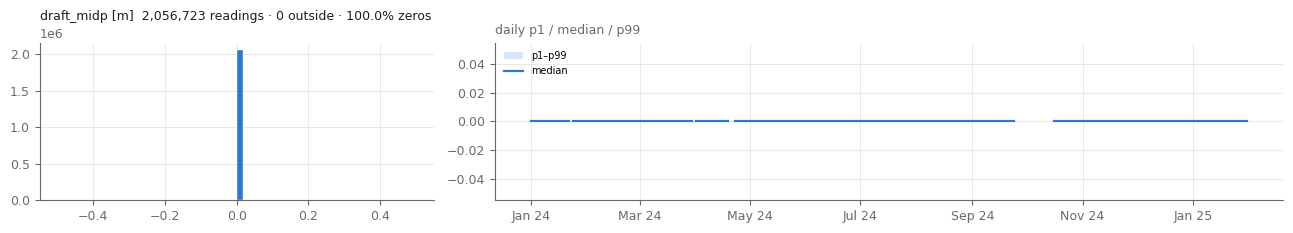

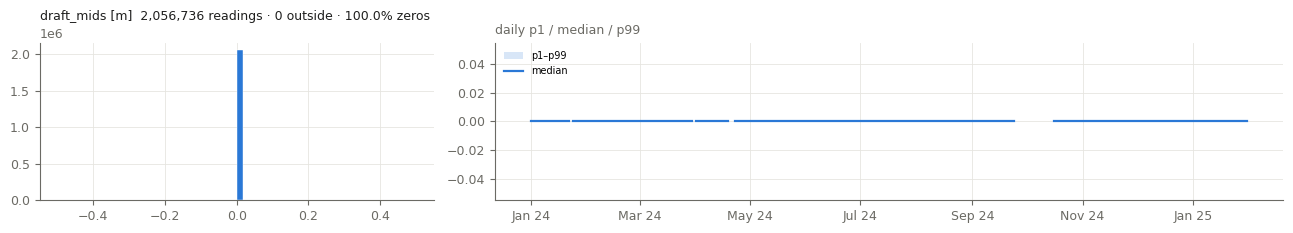

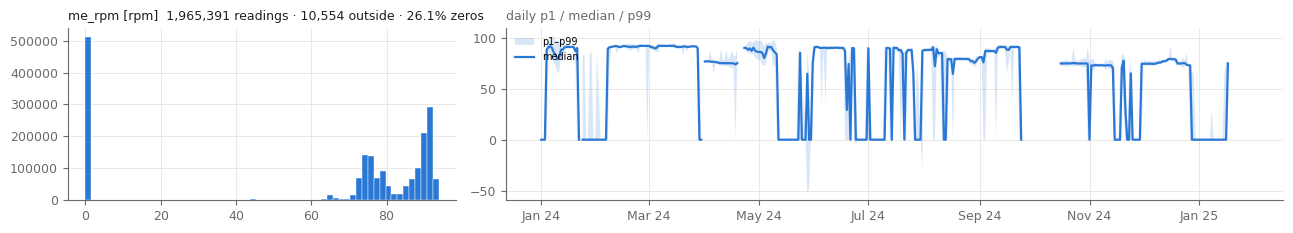

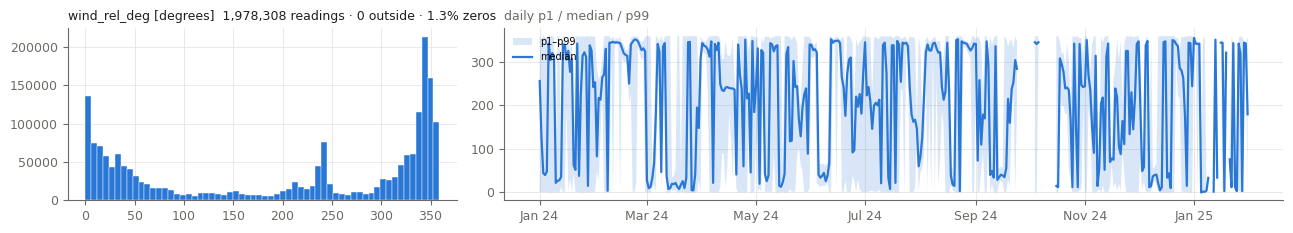

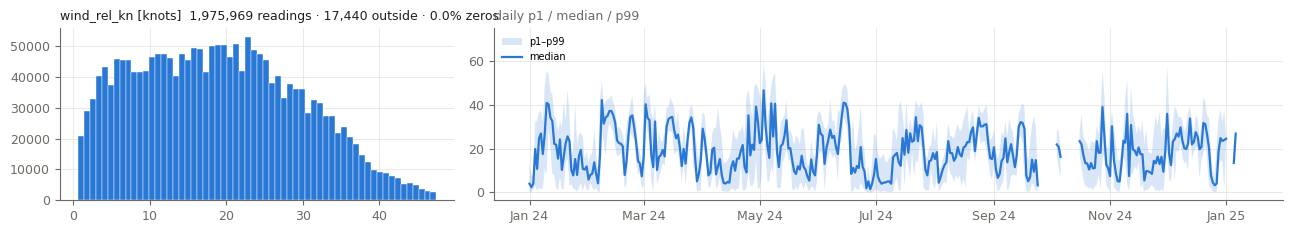

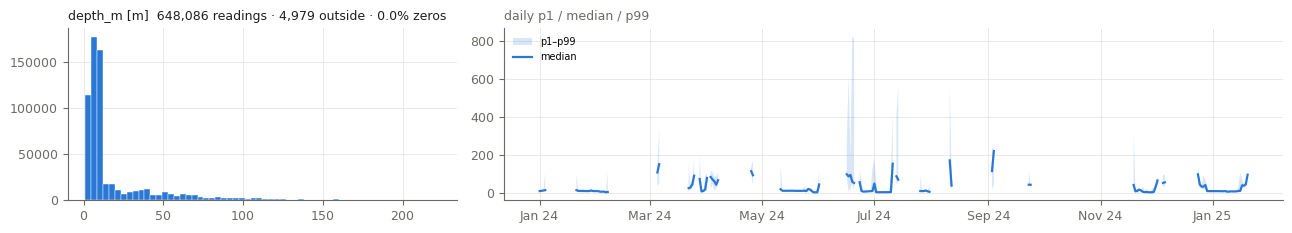

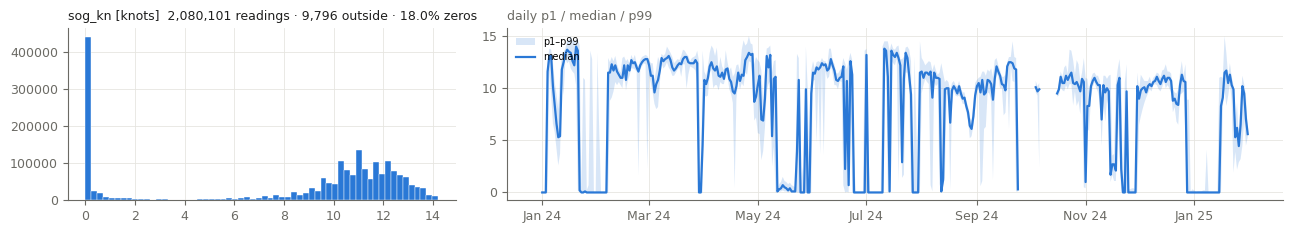

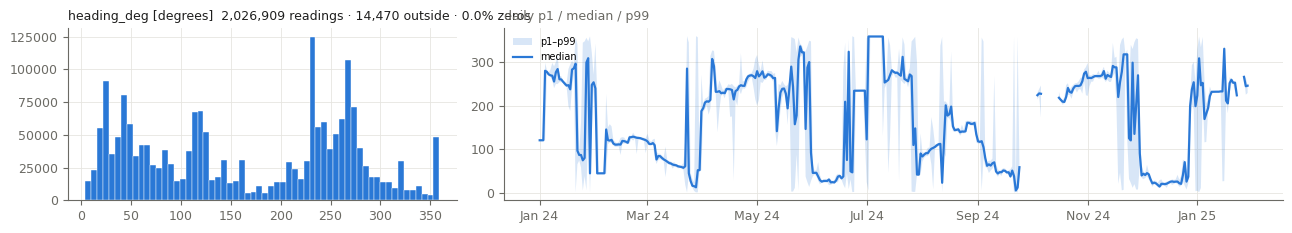

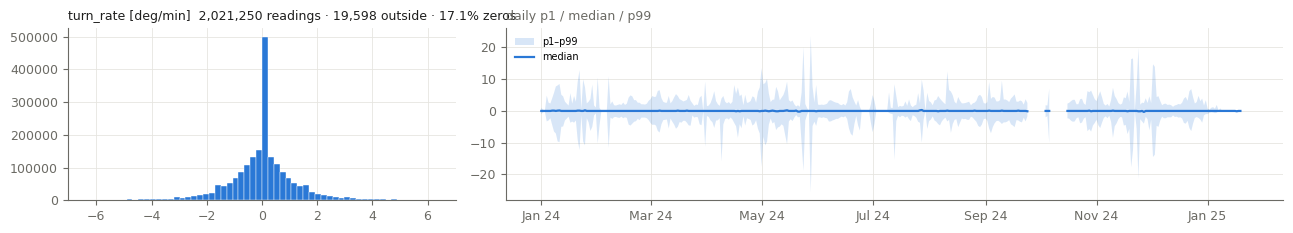

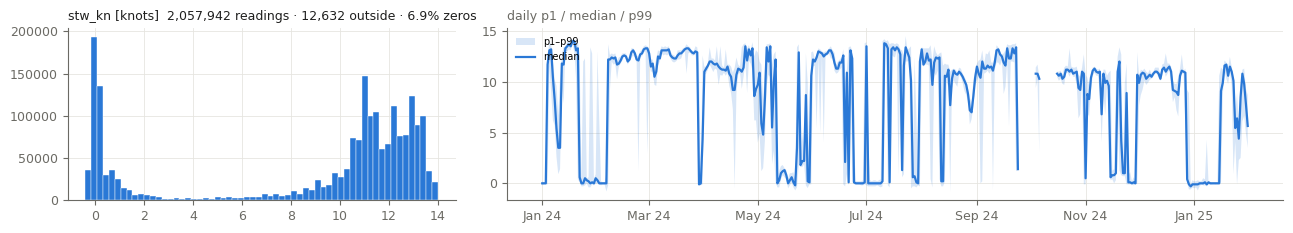

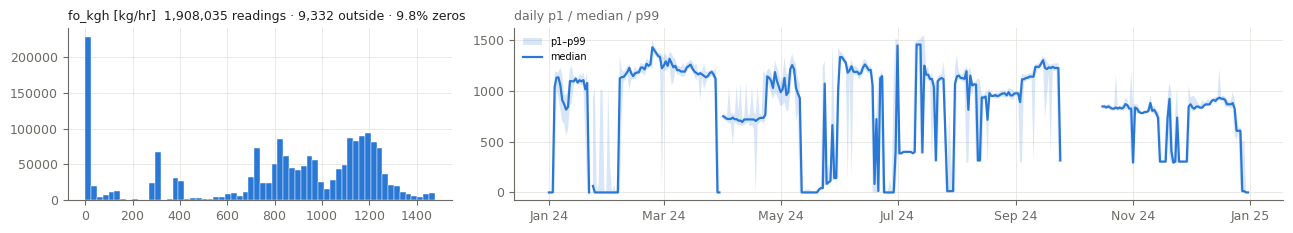

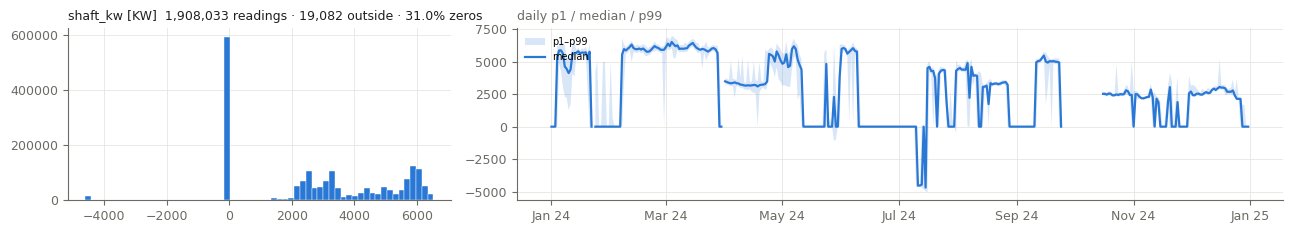

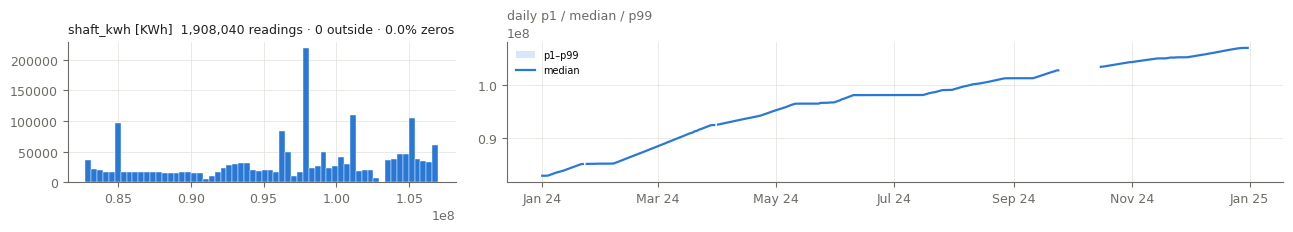

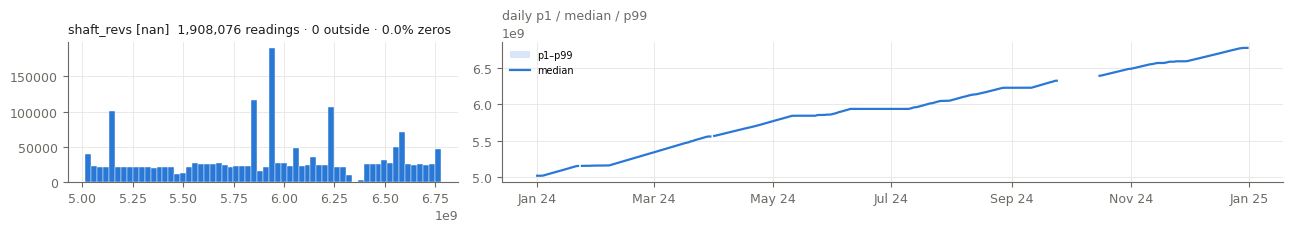

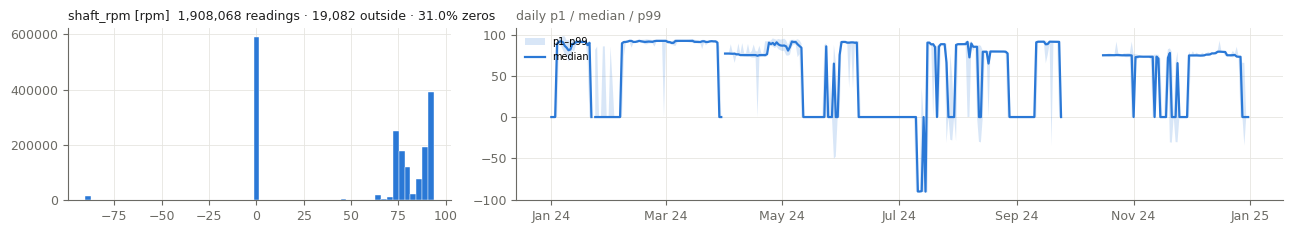

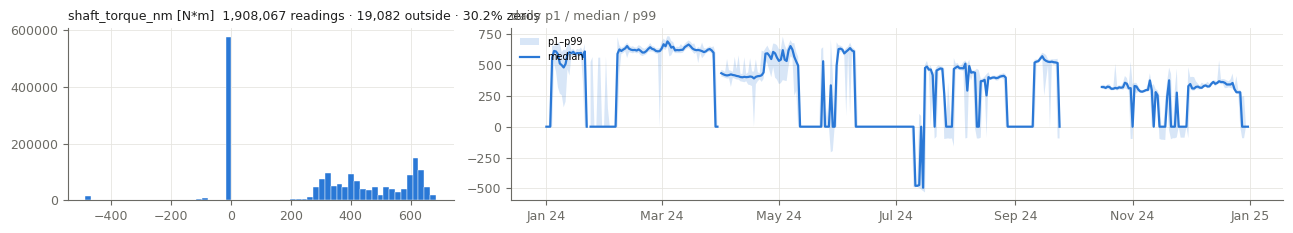

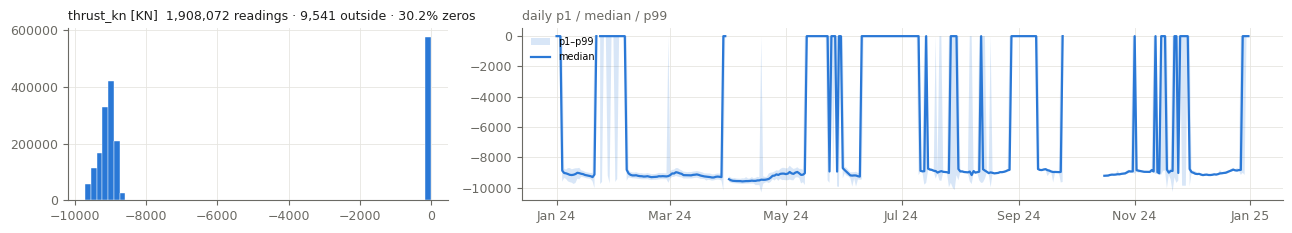

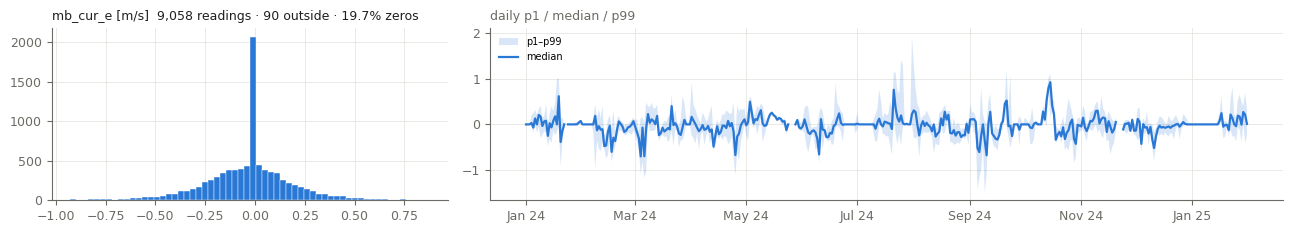

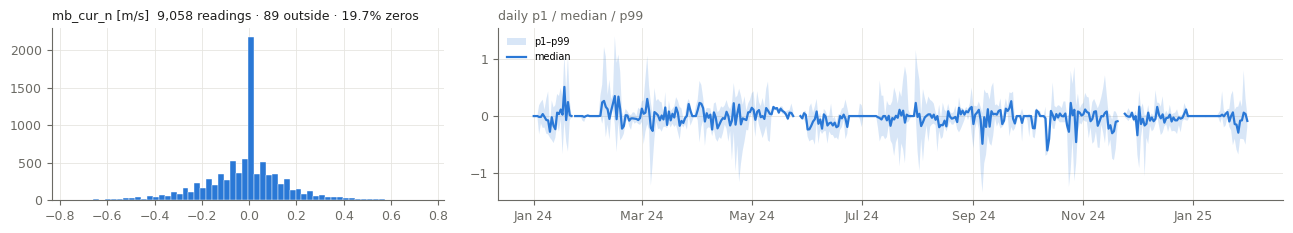

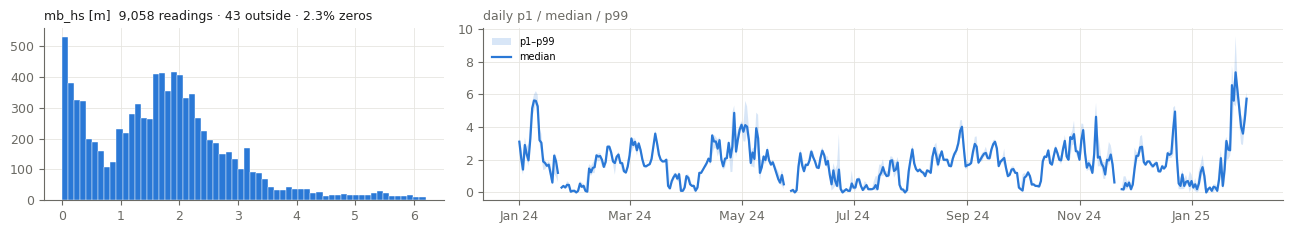

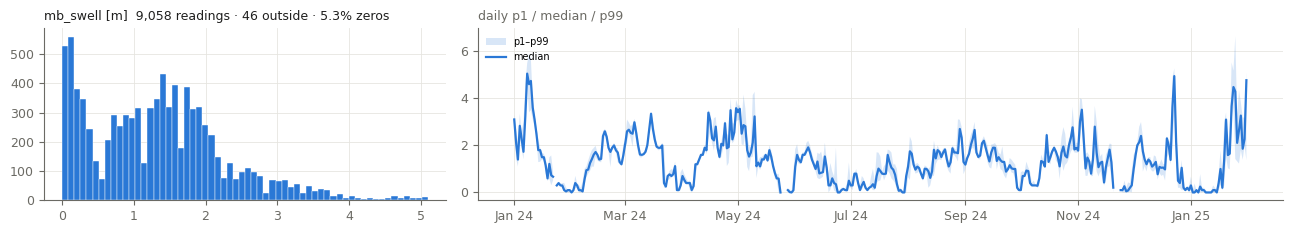

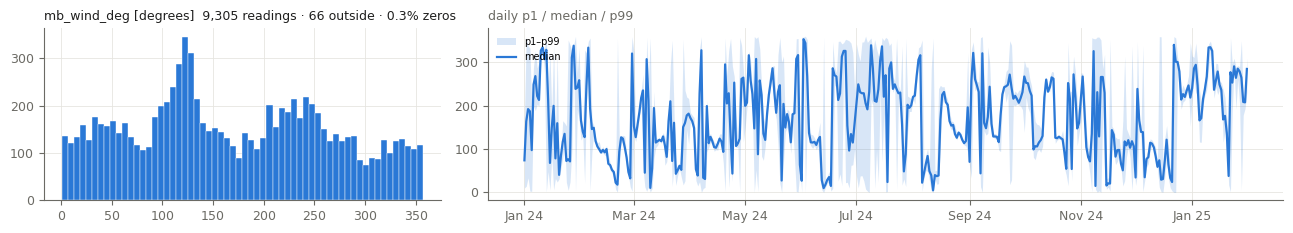

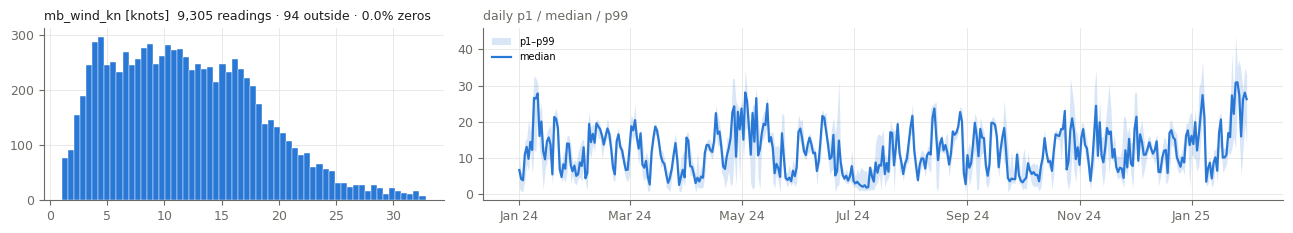

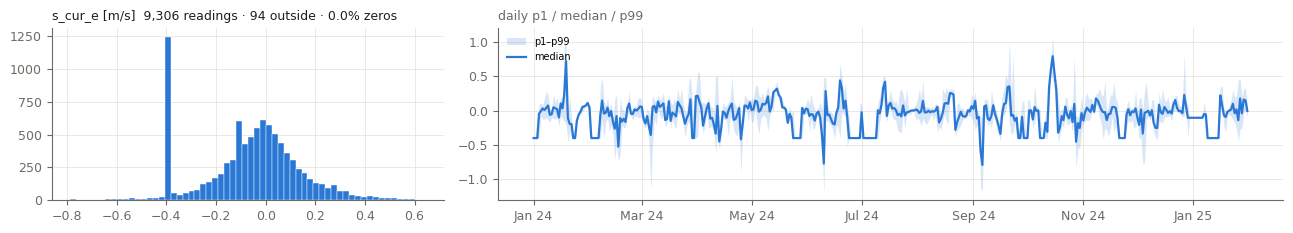

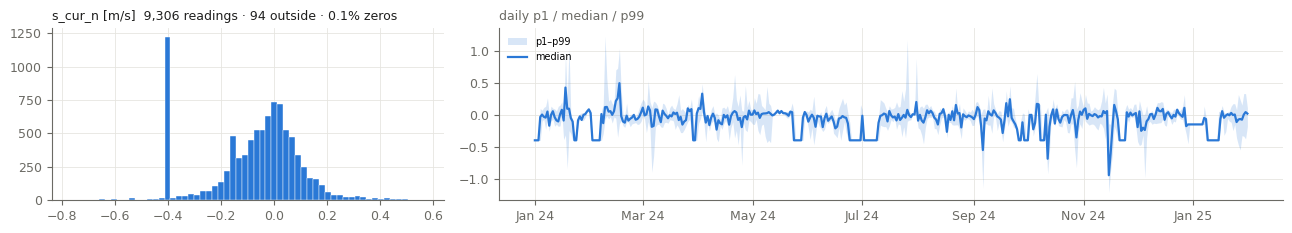

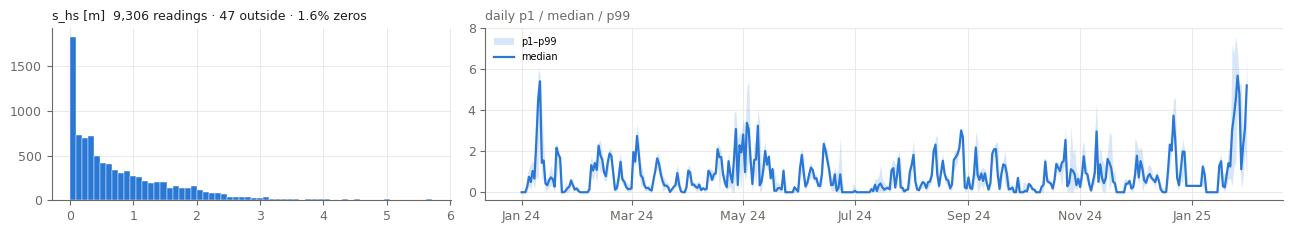

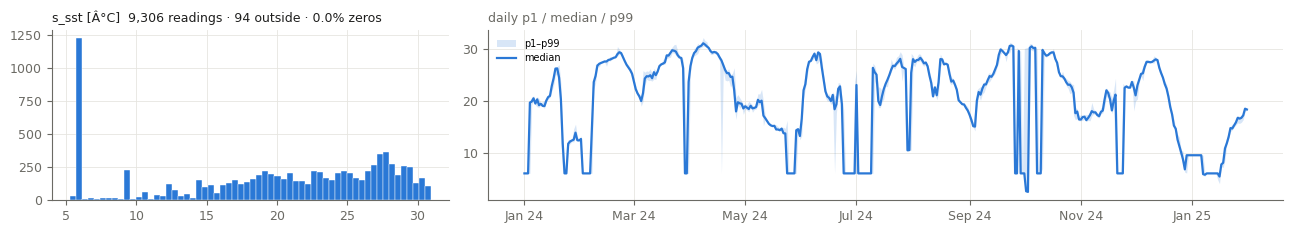

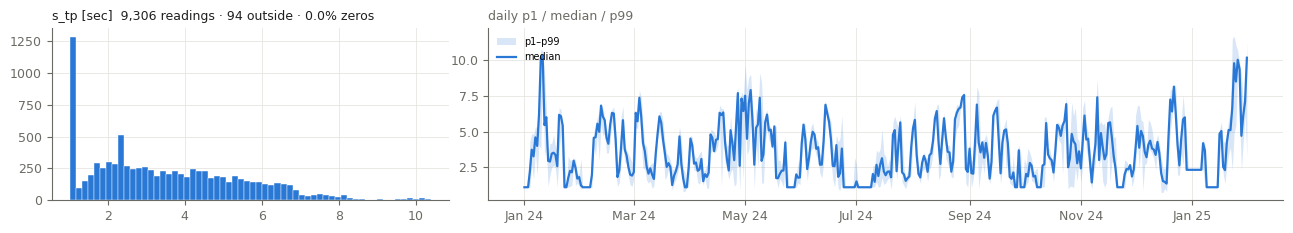

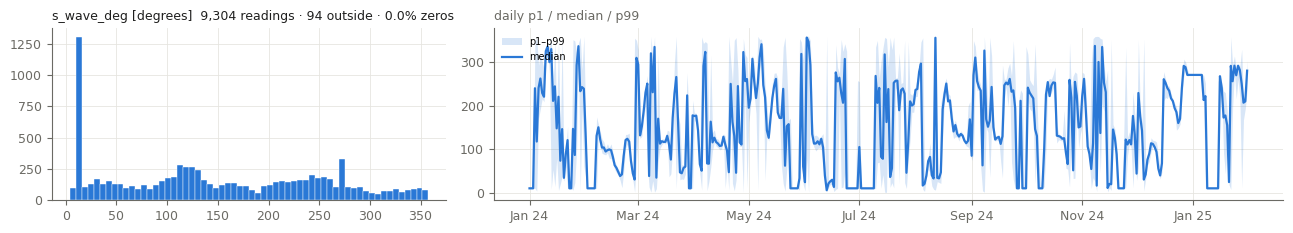

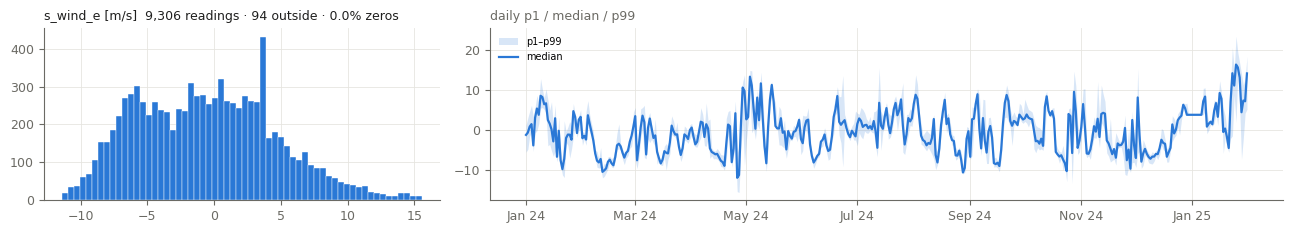

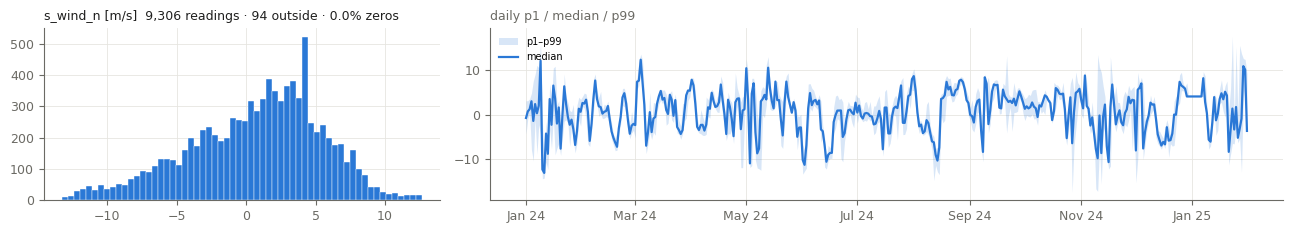

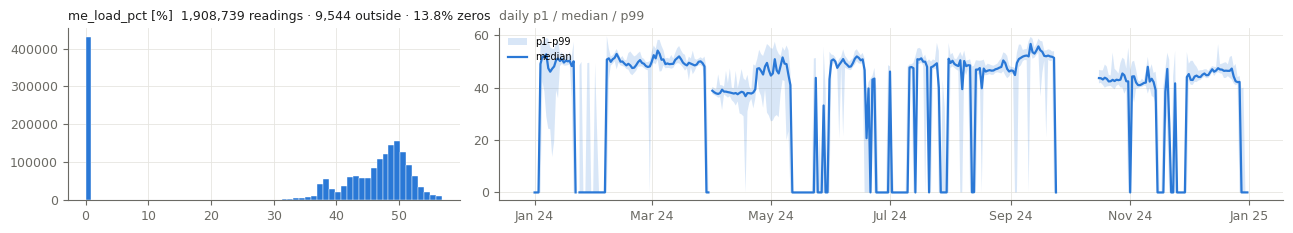

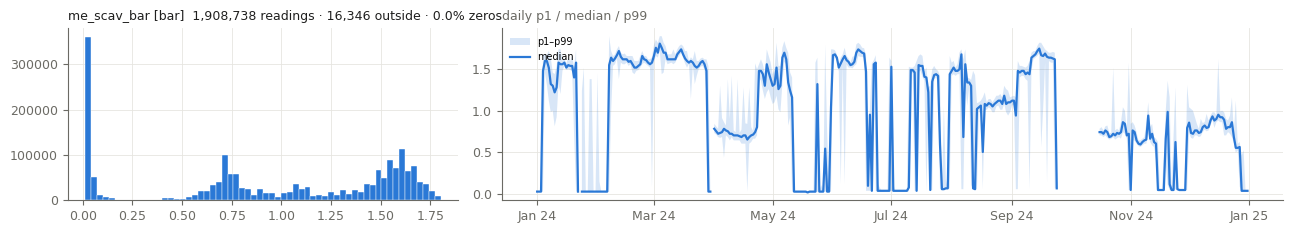

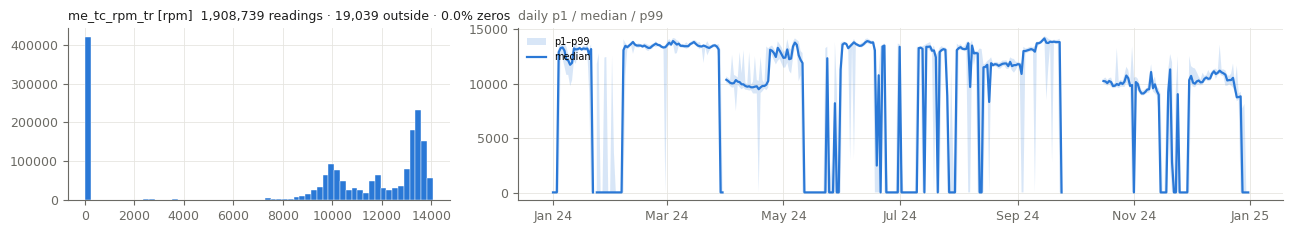

In [4]:
by_signal = {s: g for s, g in raw.groupby("signal", observed=True)}

def show(sig, bins=60):
    g = by_signal[sig]
    v = g.value.dropna()
    fig, (a, b) = plt.subplots(1, 2, figsize=(13, 2.4), gridspec_kw={"width_ratios": [1, 2]})
    unit = meta.unit.get(sig, "")
    if v.empty:
        a.text(0.5, 0.5, "no data", ha="center", transform=a.transAxes); plt.show(); return
    lo, hi = v.quantile([0.005, 0.995])
    keep = v.between(lo, hi)
    a.hist(v[keep], bins=bins, color=BLUE, edgecolor="white", linewidth=0.3)
    a.set_title(f"{sig} [{unit}]  {len(v):,} readings · {(~keep).sum():,} outside · {100 * (v == 0).mean():.1f}% zeros",
                loc="left", color=INK)
    d = g.set_index("time").value.resample("D").quantile([0.01, 0.5, 0.99]).unstack()
    b.fill_between(d.index, d[0.01], d[0.99], color=BLUE, alpha=0.18, linewidth=0, label="p1–p99")
    b.plot(d.index, d[0.5], color=BLUE, linewidth=1.6, label="median")
    b.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
    b.set_title("daily p1 / median / p99", loc="left", color=MUTED)
    b.legend(frameon=False, fontsize=7, loc="upper left")
    fig.tight_layout(); plt.show()

order = meta.sort_values(["source_name", "signal"]).index
for s in [s for s in order if s in by_signal] + [s for s in by_signal if s not in meta.index]:
    show(s)

## 4. Checks of known suspected issues

Each check counts the readings affected by one suspected issue.

In [5]:
def sig(s):
    return by_signal[s].set_index("time").value if s in by_signal else pd.Series(dtype=float)

drafts = {s: sig(s) for s in ["draft_fwd", "draft_aft", "draft_midp", "draft_mids"]}
print("Drafts: share of readings exactly 0:", {k: f"{100 * (v == 0).mean():.1f}% of {len(v):,}" for k, v in drafts.items()})

rpm, kw, tq = sig("shaft_rpm"), sig("shaft_kw"), sig("shaft_torque_nm")
neg = pd.concat({"rpm": rpm < 0, "kw": kw < 0, "torque": tq < 0}, axis=1)
neg_days = neg.any(axis=1).groupby(neg.index.tz_localize(None).normalize()).sum()
print("Negative shaft readings:", neg.sum().to_dict(), "| days with any:", list(neg_days[neg_days > 0].index.strftime("%d %b")))

j = pd.concat({"rpm": rpm, "kw": kw, "tq": tq}, axis=1, join="inner").dropna()
j = j[(j.rpm.abs() > 50) & (j.kw.abs() > 500)]
ratio = (2 * np.pi * j.rpm / 60 * j.tq) / j.kw
print(f"Torque units: 2π·n·T / P with T as logged = {ratio.median():.4f} (1 → T is kNm, 1000 → Nm) over {len(j):,} readings")

s_cols = ["s_sst", "s_cur_e", "s_cur_n", "s_tp", "s_hs", "s_wave_deg"]
w = pd.concat({c: sig(c) for c in s_cols}, axis=1)
ph = w.round(2).eq([6.0, -0.4, -0.4, 1.1, 0.01, 10.0]).all(axis=1)
print(f"Provider S placeholder rows: {ph.sum():,} of {w.dropna().shape[0]:,} hourly rows, on {ph[ph].index.normalize().nunique()} days")

jan25 = raw[raw.time >= "2025-01-01"].signal.value_counts()
print("Jan 2025 readings for power-related signals:", jan25.reindex(["shaft_kw", "shaft_torque_nm", "fo_kgh", "me_load_pct"]).fillna(0).astype(int).to_dict())

Drafts: share of readings exactly 0: {'draft_fwd': '100.0% of 2,056,727', 'draft_aft': '100.0% of 2,056,336', 'draft_midp': '100.0% of 2,056,723', 'draft_mids': '100.0% of 2,056,736'}


Negative shaft readings: {'rpm': 30275, 'kw': 30501, 'torque': 44828} | days with any: ['04 Jan', '08 Jan', '21 Jan', '24 Jan', '25 Jan', '27 Jan', '28 Jan', '29 Jan', '30 Jan', '01 Feb', '02 Feb', '07 Feb', '24 Feb', '29 Feb', '20 Mar', '29 Mar', '18 Apr', '11 May', '14 May', '16 May', '19 May', '23 May', '24 May', '26 May', '28 May', '29 May', '31 May', '10 Jul', '11 Jul', '12 Jul', '13 Jul', '14 Jul', '15 Jul', '16 Jul', '19 Jul', '21 Jul', '22 Jul', '26 Jul', '27 Jul', '28 Jul', '29 Jul', '30 Jul', '31 Jul', '06 Aug', '07 Aug', '11 Aug', '12 Aug', '13 Aug', '14 Aug', '17 Aug', '19 Sep', '23 Sep', '24 Sep', '31 Oct', '01 Nov', '15 Nov', '16 Nov', '17 Nov', '18 Nov', '20 Nov', '21 Nov', '22 Nov', '23 Nov', '24 Nov', '25 Nov', '26 Nov', '27 Nov', '28 Nov', '29 Nov', '30 Nov', '27 Dec', '28 Dec', '29 Dec', '30 Dec', '31 Dec']


Torque units: 2π·n·T / P with T as logged = 1.0000 (1 → T is kNm, 1000 → Nm) over 1,305,147 readings
Provider S placeholder rows: 1,212 of 9,304 hourly rows, on 65 days
Jan 2025 readings for power-related signals: {'shaft_kw': 0, 'shaft_torque_nm': 0, 'fo_kgh': 0, 'me_load_pct': 0}


## Next

- Split the signals between team members and go through section 3 for your own.
- Collect every issue with its evidence, then agree decisions at the team meeting.
- Only after that, decide time resolution and filters (Phase 2).